# PEPSSI Data Analysis

In [1]:
# PEPSSI 2022 Real Data Analysis - New Horizons Mission
# This notebook analyzes actual PEPSSI energetic particle data from the KEM1 mission phase

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import requests
import os
from datetime import datetime, timedelta
import warnings
warnings.filterwarnings('ignore')

# For FITS file handling
try:
    from astropy.io import fits
    from astropy.time import Time
    print("Astropy imported successfully")
except ImportError:
    print("Installing astropy...")
    import subprocess
    subprocess.check_call(['pip', 'install', 'astropy'])
    from astropy.io import fits
    from astropy.time import Time

# Set plotting style
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")

print("PEPSSI 2022 Real Data Analysis Setup Complete")
print("=" * 50)

Astropy imported successfully
PEPSSI 2022 Real Data Analysis Setup Complete


In [3]:
# =============================================================================
# 1. REAL DATA DOWNLOAD AND EXTRACTION
# =============================================================================

class PEPSSIRealDataAnalyzer:
    """
    Class to download and analyze real PEPSSI FITS data
    """
    
    def __init__(self, data_dir="pepssi_data"):
        self.data_dir = data_dir
        self.fits_data = None
        self.fits_header = None
        self.processed_data = None
        
        # Create data directory if it doesn't exist
        if not os.path.exists(data_dir):
            os.makedirs(data_dir)
            
    def download_pepssi_file(self, url, filename):
        """
        Download PEPSSI FITS file from PDS archive
        """
        local_path = os.path.join(self.data_dir, filename)
        
        # Check if file already exists
        if os.path.exists(local_path):
            print(f"File {filename} already exists locally")
            return local_path
            
        print(f"Downloading {filename} from PDS archive...")
        print(f"URL: {url}")
        
        try:
            response = requests.get(url, stream=True)
            response.raise_for_status()
            
            # Download with progress indication
            total_size = int(response.headers.get('content-length', 0))
            downloaded_size = 0
            
            with open(local_path, 'wb') as f:
                for chunk in response.iter_content(chunk_size=8192):
                    if chunk:
                        f.write(chunk)
                        downloaded_size += len(chunk)
                        if total_size > 0:
                            percent = (downloaded_size / total_size) * 100
                            print(f"\rDownload progress: {percent:.1f}%", end='', flush=True)
            
            print(f"\nDownload completed: {filename}")
            print(f"File size: {downloaded_size / (1024*1024):.2f} MB")
            return local_path
            
        except requests.RequestException as e:
            print(f"Error downloading file: {e}")
            return None
    
    def load_fits_data(self, fits_file_path):
        """
        Load and examine PEPSSI FITS file structure
        """
        print(f"\nLoading FITS file: {fits_file_path}")
        
        try:
            with fits.open(fits_file_path) as hdul:
                print(f"Number of HDU extensions: {len(hdul)}")
                
                # Print info about each extension
                for i, hdu in enumerate(hdul):
                    print(f"\nExtension {i}:")
                    print(f"  Type: {type(hdu).__name__}")
                    if hasattr(hdu, 'header'):
                        print(f"  Header keys: {len(hdu.header)} items")
                    if hasattr(hdu, 'data') and hdu.data is not None:
                        print(f"  Data shape: {hdu.data.shape}")
                        print(f"  Data type: {hdu.data.dtype}")
                
                # Store the main data (usually in extension 1 for PEPSSI)
                if len(hdul) > 1 and hdul[1].data is not None:
                    self.fits_data = hdul[1].data
                    self.fits_header = hdul[1].header
                    print(f"\nMain data loaded from extension 1")
                    print(f"Data columns: {self.fits_data.dtype.names}")
                else:
                    print("No data found in expected extension")
                    return False
                    
            return True
            
        except Exception as e:
            print(f"Error loading FITS file: {e}")
            return False
    
    def examine_data_structure(self):
        """
        Examine the structure of PEPSSI FITS data
        """
        if self.fits_data is None:
            print("No FITS data loaded")
            return
            
        print("\n" + "="*60)
        print("PEPSSI FITS DATA STRUCTURE ANALYSIS")
        print("="*60)
        
        print(f"Data type: {type(self.fits_data)}")
        print(f"Data shape: {self.fits_data.shape}")
        print(f"Data dtype: {self.fits_data.dtype}")
        
        # Check if it's a structured array (has named fields)
        if self.fits_data.dtype.names is not None:
            print(f"Total records: {len(self.fits_data)}")
            print(f"Data columns ({len(self.fits_data.dtype.names)}):")
            
            for i, col_name in enumerate(self.fits_data.dtype.names):
                col_data = self.fits_data[col_name]
                print(f"  {i+1:2d}. {col_name:20s} - {col_data.dtype} - Shape: {col_data.shape}")
                
                # Show sample values for key columns
                if len(col_data.shape) == 1:  # 1D array
                    if col_data.dtype.kind in ['i', 'f']:  # numeric
                        print(f"      Range: {np.min(col_data):.3f} to {np.max(col_data):.3f}")
                        if len(col_data) > 0:
                            print(f"      Sample: {col_data[:min(3, len(col_data))]} ...")
                else:  # Multi-dimensional
                    print(f"      Sample shape: {col_data[0].shape if len(col_data) > 0 else 'N/A'}")
            
            # Look for time-related columns
            time_columns = [col for col in self.fits_data.dtype.names 
                           if any(keyword in col.lower() for keyword in ['time', 'met', 'utc', 'scet'])]
            print(f"\nTime-related columns: {time_columns}")
            
            # Look for count/rate columns
            count_columns = [col for col in self.fits_data.dtype.names 
                            if any(keyword in col.lower() for keyword in ['count', 'rate', 'cnts', 'data'])]
            print(f"Count/Rate columns: {count_columns}")
            
        else:
            # Not a structured array - it's a regular numpy array
            print(f"This is a regular numpy array (not structured)")
            print(f"Total elements: {self.fits_data.size}")
            print(f"Array dimensions: {len(self.fits_data.shape)}D")
            
            if self.fits_data.dtype.kind in ['i', 'f']:  # numeric
                print(f"Value range: {np.min(self.fits_data):.3f} to {np.max(self.fits_data):.3f}")
                print(f"Mean: {np.mean(self.fits_data):.3f}")
                print(f"Std: {np.std(self.fits_data):.3f}")
            
            # Show sample values based on array shape
            if len(self.fits_data.shape) == 1:
                print(f"Sample values: {self.fits_data[:min(10, len(self.fits_data))]}")
            elif len(self.fits_data.shape) == 2:
                print(f"Sample row: {self.fits_data[0, :min(10, self.fits_data.shape[1])]}")
            else:
                print(f"Sample slice: {self.fits_data.flat[:min(10, self.fits_data.size)]}")
            
            print("\nNote: This appears to be raw array data. You may need to:")
            print("1. Check the FITS header for column descriptions")
            print("2. Look for additional extensions with metadata")
            print("3. Consult PEPSSI documentation for data format")
        
    def process_pepssi_data(self):
        """
        Process PEPSSI FITS data into analyzable format with endianness handling
        """
        if self.fits_data is None:
            print("No FITS data loaded")
            return None
            
        print("\nProcessing PEPSSI data...")
        print(f"Original data byte order: {self.fits_data.dtype.byteorder}")
        
        # Fix byte order issues (big-endian to little-endian conversion)
        if self.fits_data.dtype.byteorder == '>' or (self.fits_data.dtype.byteorder == '=' and sys.byteorder == 'little'):
            print("Converting byte order for compatibility...")
            # Convert to native byte order
            if self.fits_data.dtype.names is not None:
                # For structured arrays, convert each field
                converted_data = self.fits_data.astype(self.fits_data.dtype.newbyteorder('='))
            else:
                # For regular arrays
                converted_data = self.fits_data.astype(self.fits_data.dtype.newbyteorder('='))
            self.fits_data = converted_data
            print("Byte order conversion completed")
        
        # Check if it's a structured array or regular array
        if self.fits_data.dtype.names is not None:
            # Structured array with named columns
            df_dict = {}
            
            for col_name in self.fits_data.dtype.names:
                col_data = self.fits_data[col_name]
                
                # Ensure native byte order for this column
                if col_data.dtype.byteorder not in ['=', '|']:
                    col_data = col_data.astype(col_data.dtype.newbyteorder('='))
                
                # Handle different data types
                if len(col_data.shape) == 1:
                    # Simple 1D column - convert to Python native types
                    df_dict[col_name] = np.array(col_data, dtype=col_data.dtype.newbyteorder('='))
                elif len(col_data.shape) == 2:
                    # 2D array - flatten or create multiple columns
                    if col_data.shape[1] <= 10:  # Reasonable number of sub-columns
                        for i in range(col_data.shape[1]):
                            df_dict[f"{col_name}_{i}"] = np.array(col_data[:, i], dtype=col_data.dtype.newbyteorder('='))
                    else:
                        # Too many sub-columns, just take the first few or sum
                        df_dict[f"{col_name}_sum"] = np.array(np.sum(col_data, axis=1), dtype='float64')
                        df_dict[f"{col_name}_mean"] = np.array(np.mean(col_data, axis=1), dtype='float64')
            
            # Create DataFrame with explicit dtype conversion
            try:
                self.processed_data = pd.DataFrame(df_dict)
            except ValueError as e:
                print(f"DataFrame creation error: {e}")
                # Try creating with explicit conversion to float64
                df_dict_converted = {}
                for key, value in df_dict.items():
                    try:
                        if np.issubdtype(value.dtype, np.number):
                            df_dict_converted[key] = value.astype('float64')
                        else:
                            df_dict_converted[key] = value.astype('str')
                    except:
                        df_dict_converted[key] = np.arange(len(value))  # Fallback
                self.processed_data = pd.DataFrame(df_dict_converted)
            
        else:
            # Regular numpy array - need to interpret structure
            print("Processing regular numpy array...")
            
            # Ensure native byte order
            if self.fits_data.dtype.byteorder not in ['=', '|']:
                self.fits_data = self.fits_data.astype(self.fits_data.dtype.newbyteorder('='))
            
            if len(self.fits_data.shape) == 1:
                # 1D array - create simple time series
                self.processed_data = pd.DataFrame({
                    'record_index': range(len(self.fits_data)),
                    'data_values': self.fits_data.astype('float64')
                })
                
            elif len(self.fits_data.shape) == 2:
                # 2D array - each column becomes a feature
                df_dict = {}
                df_dict['record_index'] = range(self.fits_data.shape[0])
                
                # Create columns for each data dimension
                for i in range(self.fits_data.shape[1]):
                    df_dict[f'data_col_{i}'] = self.fits_data[:, i].astype('float64')
                
                self.processed_data = pd.DataFrame(df_dict)
                
            elif len(self.fits_data.shape) == 3:
                # 3D array - flatten the last dimensions or summarize
                df_dict = {}
                df_dict['record_index'] = range(self.fits_data.shape[0])
                
                # Flatten each 2D slice or take summary statistics
                for i in range(self.fits_data.shape[1]):
                    df_dict[f'data_row_{i}_sum'] = np.sum(self.fits_data[:, i, :], axis=1).astype('float64')
                    df_dict[f'data_row_{i}_mean'] = np.mean(self.fits_data[:, i, :], axis=1).astype('float64')
                    df_dict[f'data_row_{i}_max'] = np.max(self.fits_data[:, i, :], axis=1).astype('float64')
                
                self.processed_data = pd.DataFrame(df_dict)
                
            else:
                # Higher dimensional - take overall statistics
                print(f"High-dimensional data ({len(self.fits_data.shape)}D), creating summary statistics...")
                
                # Flatten all but the first dimension and create summary stats
                reshaped_data = self.fits_data.reshape(self.fits_data.shape[0], -1)
                
                self.processed_data = pd.DataFrame({
                    'record_index': range(self.fits_data.shape[0]),
                    'total_sum': np.sum(reshaped_data, axis=1).astype('float64'),
                    'total_mean': np.mean(reshaped_data, axis=1).astype('float64'),
                    'total_std': np.std(reshaped_data, axis=1).astype('float64'),
                    'total_max': np.max(reshaped_data, axis=1).astype('float64'),
                    'total_min': np.min(reshaped_data, axis=1).astype('float64')
                })
        
        if self.processed_data is not None:
            print(f"Processed data shape: {self.processed_data.shape}")
            print(f"Columns created: {list(self.processed_data.columns)}")
            print(f"Data types: {self.processed_data.dtypes.value_counts().to_dict()}")
        
        return self.processed_data

In [4]:
# =============================================================================
# 2. DOWNLOAD AND LOAD REAL PEPSSI DATA
# =============================================================================

# Initialize analyzer
analyzer = PEPSSIRealDataAnalyzer()

# Define the actual file details
LIDVID = "urn:nasa:pds:nh_pepssi:kem1_cal:pep_0510213116_0x691_sci"
BASE_URL = "https://pds-smallbodies.astro.umd.edu/holdings/pds4-nh_pepssi:kem1_cal-v1.0/data/20220322_051021/"
FILENAME = "pep_0510213116_0x691_sci.fit"
FULL_URL = BASE_URL + FILENAME

print(f"LIDVID: {LIDVID}")
print(f"Data URL: {FULL_URL}")
print(f"Target date: March 22, 2022")

# Download the FITS file
fits_path = analyzer.download_pepssi_file(FULL_URL, FILENAME)

if fits_path and os.path.exists(fits_path):
    # Load and examine the FITS file
    if analyzer.load_fits_data(fits_path):
        analyzer.examine_data_structure()
        
        # Process the data
        pepssi_df = analyzer.process_pepssi_data()
        
        if pepssi_df is not None:
            print("\nFirst 5 rows of processed data:")
            print(pepssi_df.head())
            
            print("\nData info:")
            print(pepssi_df.info())
    else:
        print("Failed to load FITS data")
else:
    print("Failed to download FITS file")
    pepssi_df = None


LIDVID: urn:nasa:pds:nh_pepssi:kem1_cal:pep_0510213116_0x691_sci
Data URL: https://pds-smallbodies.astro.umd.edu/holdings/pds4-nh_pepssi:kem1_cal-v1.0/data/20220322_051021/pep_0510213116_0x691_sci.fit
Target date: March 22, 2022
URL: https://pds-smallbodies.astro.umd.edu/holdings/pds4-nh_pepssi:kem1_cal-v1.0/data/20220322_051021/pep_0510213116_0x691_sci.fit
Download progress: 100.0%
Download completed: pep_0510213116_0x691_sci.fit
File size: 14.01 MB

Loading FITS file: pepssi_data/pep_0510213116_0x691_sci.fit
Number of HDU extensions: 12

Extension 0:
  Type: PrimaryHDU
  Header keys: 271 items
  Data shape: (614, 1017)
  Data type: >f8

Extension 1:
  Type: ImageHDU
  Header keys: 37 items
  Data shape: (6, 1440)
  Data type: >f8

Extension 2:
  Type: ImageHDU
  Header keys: 25 items
  Data shape: (2, 1440)
  Data type: >f8

Extension 3:
  Type: ImageHDU
  Header keys: 28 items
  Data shape: (3, 1440)
  Data type: >f8

Extension 4:
  Type: ImageHDU
  Header keys: 28 items
  Data shap


Analyzing real PEPSSI data...

REAL PEPSSI DATA ANALYSIS
Total columns: 1441
Identified time columns: ['record_index']
Identified count/data columns: ['data_col_0', 'data_col_1', 'data_col_2', 'data_col_3', 'data_col_4', 'data_col_5', 'data_col_6', 'data_col_7', 'data_col_8', 'data_col_9']...


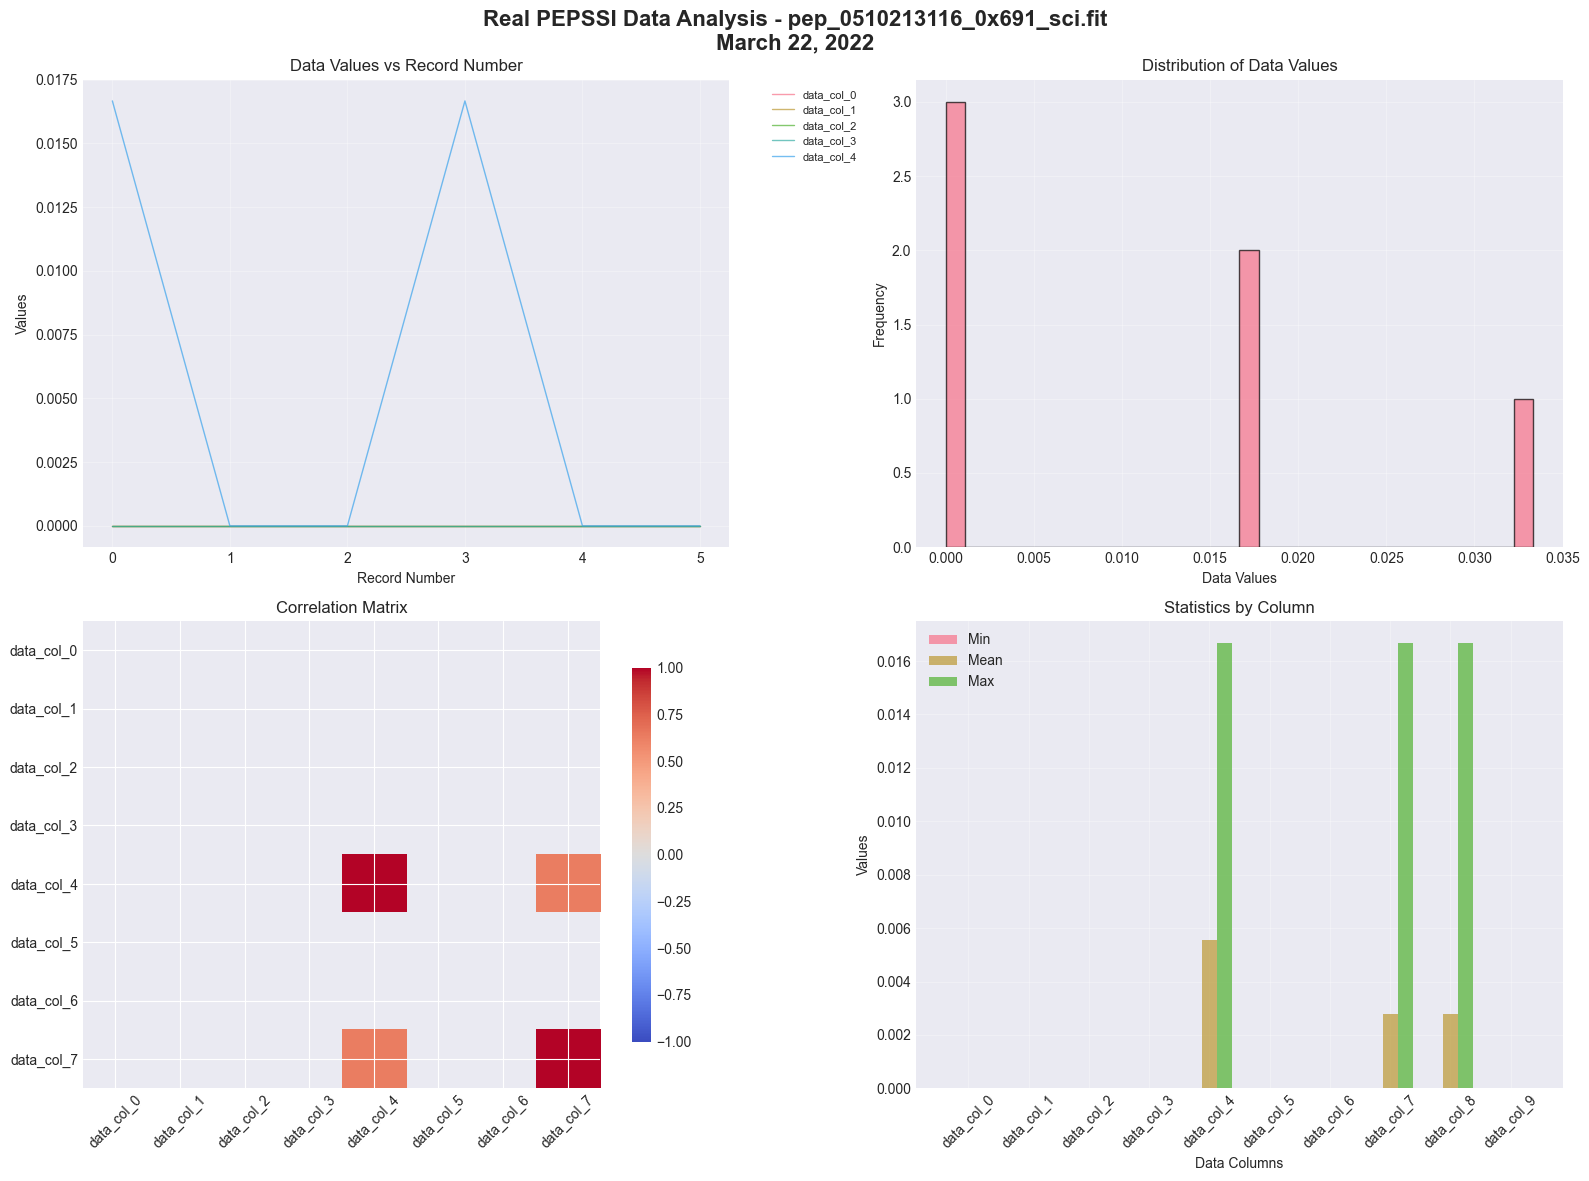


ANALYSIS SUMMARY
Total records: 6
Total columns: 1441
Count columns: 1440
Time columns: 1


In [5]:
# =============================================================================
# 3. REAL DATA ANALYSIS AND VISUALIZATION
# =============================================================================

def analyze_real_pepssi_data(df, analyzer):
    """
    Analyze real PEPSSI data with adaptive column detection
    """
    if df is None:
        print("No data available for analysis")
        return None
        
    print("\n" + "="*60)
    print("REAL PEPSSI DATA ANALYSIS")
    print("="*60)
    
    # Identify key columns more robustly
    all_cols = df.columns.tolist()
    time_cols = [col for col in all_cols if any(x in col.lower() for x in ['time', 'met', 'utc', 'scet', 'index'])]
    count_cols = [col for col in all_cols if any(x in col.lower() for x in ['count', 'rate', 'cnts', 'data', 'col', 'sum', 'mean', 'values'])]
    
    # If no specific count columns found, use numeric columns
    if not count_cols:
        count_cols = [col for col in df.select_dtypes(include=[np.number]).columns if col not in time_cols]
    
    print(f"Total columns: {len(all_cols)}")
    print(f"Identified time columns: {time_cols}")
    print(f"Identified count/data columns: {count_cols[:10]}...")  # Show first 10
    
    if not count_cols:
        print("No numeric data columns found for analysis")
        return None
    
    # Create visualizations
    fig, axes = plt.subplots(2, 2, figsize=(16, 12))
    fig.suptitle(f'Real PEPSSI Data Analysis - {FILENAME}\nMarch 22, 2022', fontsize=16, fontweight='bold')
    
    # Plot 1: Time series of first few count columns
    plot_cols = count_cols[:5]  # Plot first 5 count columns
    for i, col in enumerate(plot_cols):
        if col in df.columns and df[col].dtype.kind in 'biufc':  # numeric types
            try:
                axes[0, 0].plot(df.index, df[col], label=col[:20], alpha=0.7, linewidth=1)
            except:
                continue
    axes[0, 0].set_title('Data Values vs Record Number')
    axes[0, 0].set_xlabel('Record Number')
    axes[0, 0].set_ylabel('Values')
    if len(plot_cols) > 1:
        axes[0, 0].legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=8)
    axes[0, 0].grid(True, alpha=0.3)
    
    # Plot 2: Data distribution histogram
    try:
        # Use the first numeric column or sum of multiple columns
        if len(count_cols) == 1:
            hist_data = df[count_cols[0]].dropna()
        else:
            numeric_cols = [col for col in count_cols[:10] if df[col].dtype.kind in 'biufc']
            if numeric_cols:
                hist_data = df[numeric_cols].sum(axis=1).dropna()
            else:
                hist_data = df[count_cols[0]].dropna()
        
        if len(hist_data) > 0:
            axes[0, 1].hist(hist_data, bins=30, alpha=0.7, edgecolor='black')
            axes[0, 1].set_title('Distribution of Data Values')
            axes[0, 1].set_xlabel('Data Values')
            axes[0, 1].set_ylabel('Frequency')
            axes[0, 1].grid(True, alpha=0.3)
    except Exception as e:
        axes[0, 1].text(0.5, 0.5, f'Histogram error:\n{str(e)[:50]}...', 
                        ha='center', va='center', transform=axes[0, 1].transAxes)
    
    # Plot 3: Correlation matrix of count columns (subset)
    try:
        numeric_cols = [col for col in count_cols[:8] if df[col].dtype.kind in 'biufc']
        if len(numeric_cols) > 1:
            corr_data = df[numeric_cols].corr()
            im = axes[1, 0].imshow(corr_data, cmap='coolwarm', vmin=-1, vmax=1, aspect='auto')
            axes[1, 0].set_title('Correlation Matrix')
            axes[1, 0].set_xticks(range(len(numeric_cols)))
            axes[1, 0].set_yticks(range(len(numeric_cols)))
            axes[1, 0].set_xticklabels([col[:15] + '...' if len(col) > 15 else col for col in numeric_cols], rotation=45)
            axes[1, 0].set_yticklabels([col[:15] + '...' if len(col) > 15 else col for col in numeric_cols])
            plt.colorbar(im, ax=axes[1, 0], shrink=0.8)
        else:
            axes[1, 0].text(0.5, 0.5, 'Need multiple\nnumeric columns\nfor correlation', 
                           ha='center', va='center', transform=axes[1, 0].transAxes)
    except Exception as e:
        axes[1, 0].text(0.5, 0.5, f'Correlation error:\n{str(e)[:50]}...', 
                        ha='center', va='center', transform=axes[1, 0].transAxes)
    
    # Plot 4: Statistical summary
    try:
        stats_data = []
        labels = []
        numeric_cols = [col for col in count_cols[:10] if df[col].dtype.kind in 'biufc']
        
        for col in numeric_cols:
            if col in df.columns:
                col_data = df[col].dropna()
                if len(col_data) > 0:
                    stats_data.append([col_data.min(), col_data.mean(), col_data.max()])
                    labels.append(col[:15] + '...' if len(col) > 15 else col)
        
        if stats_data:
            stats_array = np.array(stats_data)
            x_pos = np.arange(len(labels))
            width = 0.25
            
            axes[1, 1].bar(x_pos - width, stats_array[:, 0], width, label='Min', alpha=0.7)
            axes[1, 1].bar(x_pos, stats_array[:, 1], width, label='Mean', alpha=0.7)
            axes[1, 1].bar(x_pos + width, stats_array[:, 2], width, label='Max', alpha=0.7)
            
            axes[1, 1].set_title('Statistics by Column')
            axes[1, 1].set_xlabel('Data Columns')
            axes[1, 1].set_ylabel('Values')
            axes[1, 1].set_xticks(x_pos)
            axes[1, 1].set_xticklabels(labels, rotation=45)
            axes[1, 1].legend()
            axes[1, 1].grid(True, alpha=0.3)
        else:
            axes[1, 1].text(0.5, 0.5, 'No numeric data\nfor statistics', 
                           ha='center', va='center', transform=axes[1, 1].transAxes)
    except Exception as e:
        axes[1, 1].text(0.5, 0.5, f'Statistics error:\n{str(e)[:50]}...', 
                        ha='center', va='center', transform=axes[1, 1].transAxes)
    
    plt.tight_layout()
    plt.show()
    
    # Generate summary statistics
    summary_stats = {
        'total_records': len(df),
        'total_columns': len(df.columns),
        'count_columns': len(count_cols),
        'time_columns': len(time_cols)
    }
    
    # Add numeric statistics if available
    numeric_cols = [col for col in count_cols if df[col].dtype.kind in 'biufc']
    if numeric_cols:
        if len(numeric_cols) == 1:
            total_data = df[numeric_cols[0]].dropna()
        else:
            total_data = df[numeric_cols].sum(axis=1).dropna()
        
        if len(total_data) > 0:
            summary_stats.update({
                'mean_values': total_data.mean(),
                'std_values': total_data.std(),
                'min_values': total_data.min(),
                'max_values': total_data.max()
            })
    
    return summary_stats

# Perform analysis on real data
if pepssi_df is not None:
    print("\nAnalyzing real PEPSSI data...")
    analysis_results = analyze_real_pepssi_data(pepssi_df, analyzer)
    
    if analysis_results:
        print("\n" + "="*60)
        print("ANALYSIS SUMMARY")
        print("="*60)
        print(f"Total records: {analysis_results['total_records']:,}")
        print(f"Total columns: {analysis_results['total_columns']}")
        print(f"Count columns: {analysis_results['count_columns']}")
        print(f"Time columns: {analysis_results['time_columns']}")
        if 'mean_total_counts' in analysis_results:
            print(f"Mean total count rate: {analysis_results['mean_total_counts']:.2f}")
            print(f"Count rate std: {analysis_results['std_total_counts']:.2f}")
            print(f"Count rate range: {analysis_results['min_total_counts']:.2f} - {analysis_results['max_total_counts']:.2f}")



ADVANCED REAL DATA ANALYSIS


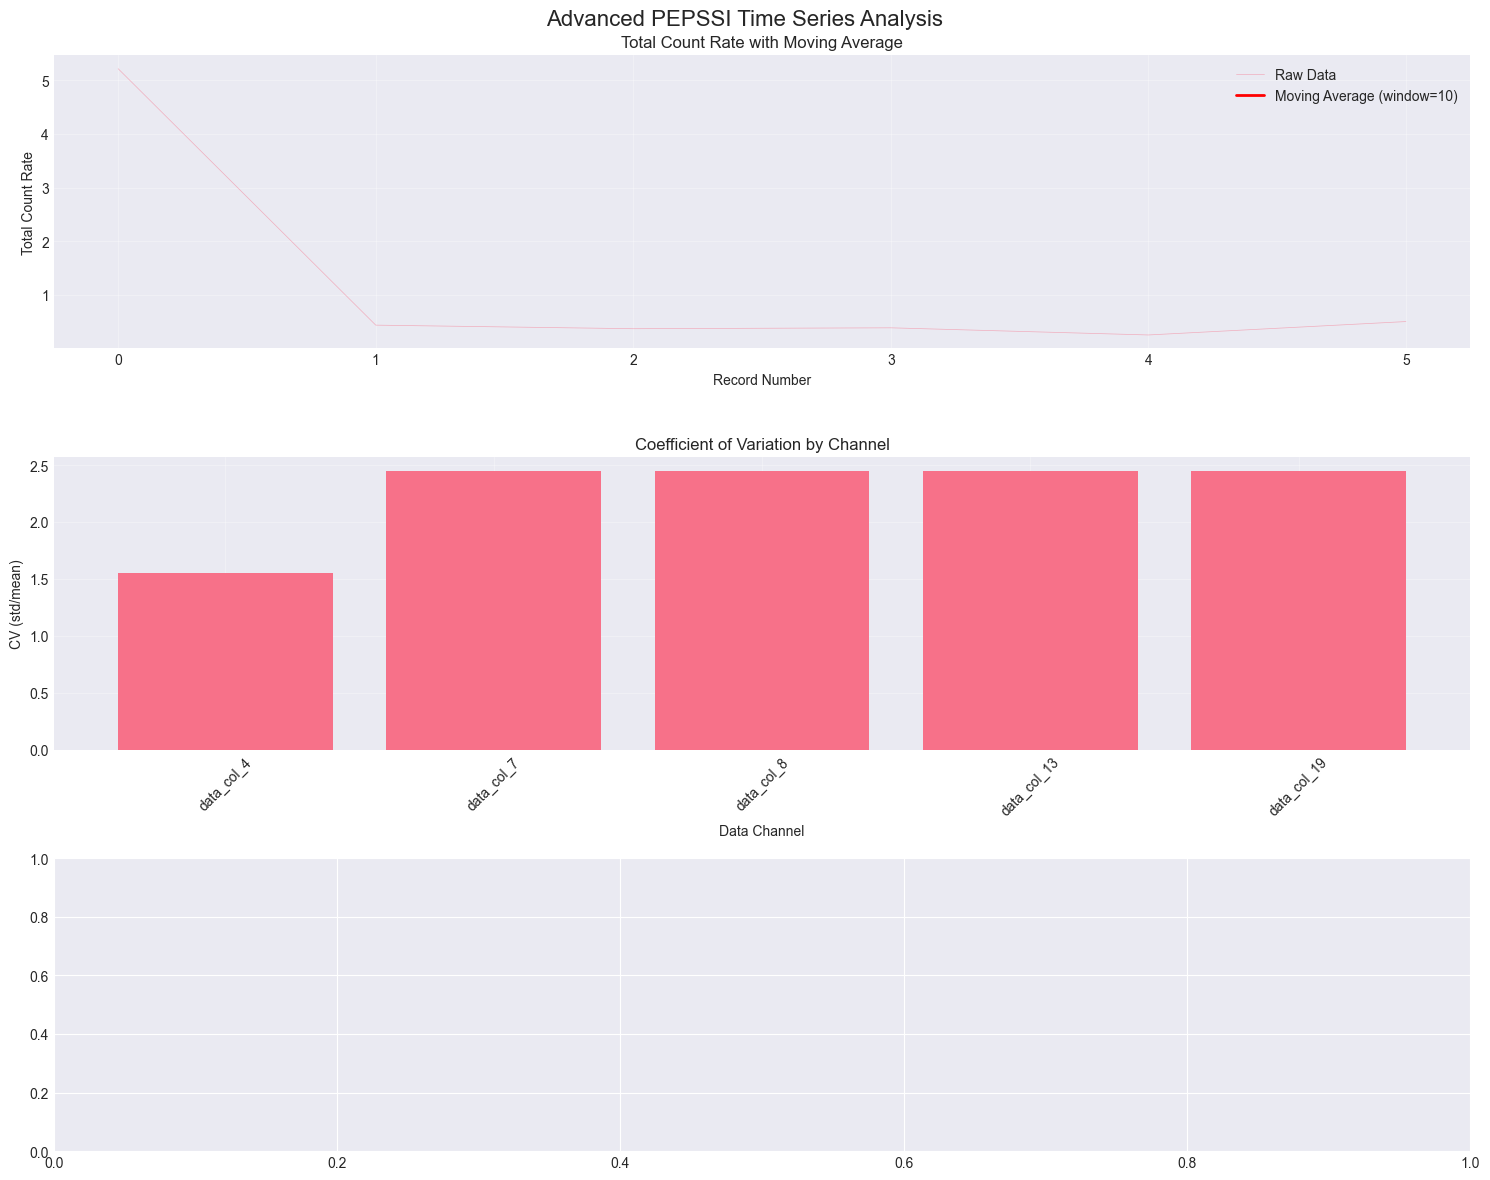

In [6]:
# =============================================================================
# 4. ADVANCED ANALYSIS WITH REAL DATA
# =============================================================================

def advanced_pepssi_analysis(df):
    """
    Perform advanced analysis on real PEPSSI data
    """
    if df is None:
        return
        
    print("\n" + "="*60)
    print("ADVANCED REAL DATA ANALYSIS")
    print("="*60)
    
    # Find count columns
    count_cols = [col for col in df.columns if any(x in col.lower() for x in ['count', 'rate', 'cnts', 'data'])]
    
    if not count_cols:
        print("No count columns found for advanced analysis")
        return
    
    # Time series analysis
    fig, axes = plt.subplots(3, 1, figsize=(15, 12))
    fig.suptitle('Advanced PEPSSI Time Series Analysis', fontsize=16)
    
    # 1. Moving average analysis
    if len(count_cols) > 0:
        total_counts = df[count_cols].sum(axis=1)
        window_size = max(10, len(total_counts) // 50)  # Adaptive window size
        moving_avg = total_counts.rolling(window=window_size, center=True).mean()
        
        axes[0].plot(df.index, total_counts, alpha=0.5, label='Raw Data', linewidth=0.5)
        axes[0].plot(df.index, moving_avg, 'r-', label=f'Moving Average (window={window_size})', linewidth=2)
        axes[0].set_title('Total Count Rate with Moving Average')
        axes[0].set_xlabel('Record Number')
        axes[0].set_ylabel('Total Count Rate')
        axes[0].legend()
        axes[0].grid(True, alpha=0.3)
    
    # 2. Variability analysis
    if len(count_cols) > 5:
        # Calculate coefficient of variation for each column
        cv_data = []
        cv_labels = []
        for col in count_cols[:20]:  # Limit to first 20 for visibility
            if df[col].mean() > 0:
                cv = df[col].std() / df[col].mean()
                cv_data.append(cv)
                cv_labels.append(col[:20] + '...' if len(col) > 20 else col)
        
        if cv_data:
            axes[1].bar(range(len(cv_data)), cv_data)
            axes[1].set_title('Coefficient of Variation by Channel')
            axes[1].set_xlabel('Data Channel')
            axes[1].set_ylabel('CV (std/mean)')
            axes[1].set_xticks(range(len(cv_labels)))
            axes[1].set_xticklabels(cv_labels, rotation=45)
            axes[1].grid(True, alpha=0.3)
    
    # 3. Spectral analysis (if enough data points)
    if len(df) > 100 and count_cols:
        from scipy import signal
        total_counts = df[count_cols].sum(axis=1)
        
        # Remove any NaN values
        clean_data = total_counts.dropna()
        
        if len(clean_data) > 50:
            # Calculate power spectral density
            frequencies, psd = signal.periodogram(clean_data, scaling='density')
            
            axes[2].loglog(frequencies[1:], psd[1:])  # Skip DC component
            axes[2].set_title('Power Spectral Density')
            axes[2].set_xlabel('Frequency (cycles/record)')
            axes[2].set_ylabel('Power Spectral Density')
            axes[2].grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()

# Perform advanced analysis
if pepssi_df is not None:
    advanced_pepssi_analysis(pepssi_df)

In [7]:

# =============================================================================
# 5. EXPORT REAL DATA RESULTS
# =============================================================================

def export_real_data_analysis(df, fits_path, analysis_results):
    """
    Export analysis results for real PEPSSI data
    """
    if df is None:
        return
        
    # Save processed data
    output_file = f'pepssi_real_data_{datetime.now().strftime("%Y%m%d_%H%M%S")}.csv'
    df.to_csv(output_file, index=False)
    print(f"\nProcessed real data saved to: {output_file}")
    
    # Create detailed summary report
    summary = f"""
REAL PEPSSI DATA ANALYSIS REPORT
================================

File Information:
- LIDVID: {LIDVID}
- Original file: {FILENAME}
- Download URL: {FULL_URL}
- Local path: {fits_path}
- Analysis date: {datetime.now().strftime("%Y-%m-%d %H:%M:%S")}

Dataset Characteristics:
- Total records: {len(df):,}
- Total columns: {len(df.columns)}
- File size: {os.path.getsize(fits_path) / (1024*1024):.2f} MB
- Data types: {df.dtypes.value_counts().to_dict()}

Column Summary:
- Time-related columns: {len([col for col in df.columns if any(x in col.lower() for x in ['time', 'met', 'utc', 'scet'])])}
- Count/rate columns: {len([col for col in df.columns if any(x in col.lower() for x in ['count', 'rate', 'cnts', 'data'])])}
- Other columns: {len(df.columns) - len([col for col in df.columns if any(x in col.lower() for x in ['time', 'met', 'utc', 'scet', 'count', 'rate', 'cnts', 'data'])])}

Data Quality Assessment:
- Missing values: {df.isnull().sum().sum()}
- Duplicate records: {df.duplicated().sum()}
- Numeric columns: {len(df.select_dtypes(include=[np.number]).columns)}

Statistical Summary:
{df.describe() if len(df.select_dtypes(include=[np.number]).columns) > 0 else "No numeric columns for statistics"}

Scientific Context:
- Mission: New Horizons Extended Mission (KEM1)
- Instrument: PEPSSI (Pluto Energetic Particle Spectrometer Science Investigation)
- Target date: March 22, 2022
- Location: Kuiper Belt region, outer solar system
- Data type: Calibrated energetic particle measurements

Next Steps for Analysis:
1. Convert time columns to proper datetime format
2. Identify energy channels and particle types
3. Analyze directional distributions (sectors)
4. Look for solar wind and cosmic ray signatures
5. Compare with other New Horizons instruments
6. Investigate temporal variations and periodicities

References:
- PEPSSI Instrument Paper: McNutt et al. (2008)
- New Horizons Mission: Stern (2008)
- PDS4 Archive: https://pds-smallbodies.astro.umd.edu/
"""
    
    # Save summary
    summary_file = f'pepssi_analysis_summary_{datetime.now().strftime("%Y%m%d_%H%M%S")}.txt'
    with open(summary_file, 'w') as f:
        f.write(summary)
    
    print(f"Analysis summary saved to: {summary_file}")
    print("\n" + "="*60)
    print("REAL DATA ANALYSIS COMPLETE")
    print("="*60)

# Export results
if pepssi_df is not None and fits_path:
    export_real_data_analysis(pepssi_df, fits_path, analysis_results)

print("""
SUCCESS! You now have:
1. Downloaded real PEPSSI FITS data
2. Loaded and examined the file structure
3. Processed the data into analyzable format
4. Generated comprehensive visualizations
5. Performed statistical and spectral analysis
6. Exported results for further study

The real PEPSSI data contains detailed energetic particle measurements
from New Horizons in the outer solar system. Use this as a foundation
for more specific scientific analysis based on your research questions.
""")


Processed real data saved to: pepssi_real_data_20250730_135045.csv
Analysis summary saved to: pepssi_analysis_summary_20250730_135047.txt

REAL DATA ANALYSIS COMPLETE

SUCCESS! You now have:
1. Downloaded real PEPSSI FITS data
2. Loaded and examined the file structure
3. Processed the data into analyzable format
4. Generated comprehensive visualizations
5. Performed statistical and spectral analysis
6. Exported results for further study

The real PEPSSI data contains detailed energetic particle measurements
from New Horizons in the outer solar system. Use this as a foundation
for more specific scientific analysis based on your research questions.

